## Problem Statement

Why does stroke remain significant global health issue despite advances in medical science? The goal of this analysis is to explore a dataset that capture key variables like age, gender,
lifestyle, and medical history to identify patterns and predictors of stroke. By examining the data,
we can uncover potential insights that may aid in early detection or risk mitigation strategies.

## Overview
- **Explore the Dataset**: Understand the structure, variables, and any gaps or anomalies in the data.
- **Perform Data Cleaning**: Ensure the dataset is ready for analysis by addressing missing values, outliers, or inconsistencis.
- **Conduct Exploratory Data Analysis(EDA)**: Use visualizations and statistical tools to identify trends and relationships.
- **Presentaion**: Communication of findings through storytelling and presentation tools.
- **Discuss Implication**: Interpret the findings and their potential impact on healthcare strategies.
- **Recommendation**: Summerizing the findings to highlight critical insights that could inform healthcare policies and interventions.

#### import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Load the data

In [2]:
health_data = pd.read_csv("healthcare-dataset-stroke-data.csv")

health_data

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
...,...,...,...,...,...,...,...,...,...,...,...,...
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0


### Get used to the data

In [4]:
health_data.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

In [5]:
health_data.dtypes

id                     int64
gender                object
age                  float64
hypertension           int64
heart_disease          int64
ever_married          object
work_type             object
Residence_type        object
avg_glucose_level    float64
bmi                  float64
smoking_status        object
stroke                 int64
dtype: object

In [6]:
health_data.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [7]:
health_data.duplicated().sum()

0

In [8]:
health_data.isna().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

<Axes: >

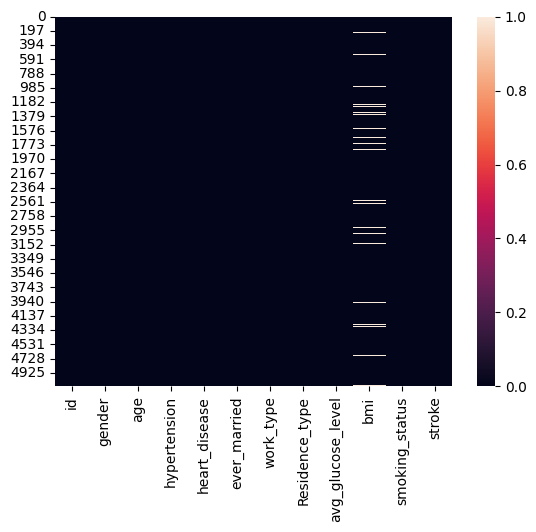

In [9]:
sns.heatmap(health_data.isna())

### Clean the Data

In [10]:
health_data.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [11]:
health_data.dropna(inplace = True)

In [12]:
health_data

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
5,56669,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1
...,...,...,...,...,...,...,...,...,...,...,...,...
5104,14180,Female,13.0,0,0,No,children,Rural,103.08,18.6,Unknown,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0


In [13]:
health_data.isna().sum()

id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

#### Exploratory Data Analysis(EDA)

##### What is the distribution of strokes across different age groups?

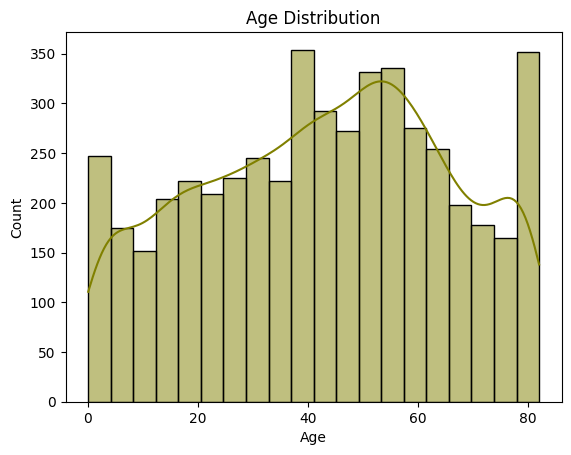

In [14]:
sns.histplot(health_data['age'], kde= True, color='olive')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.show()

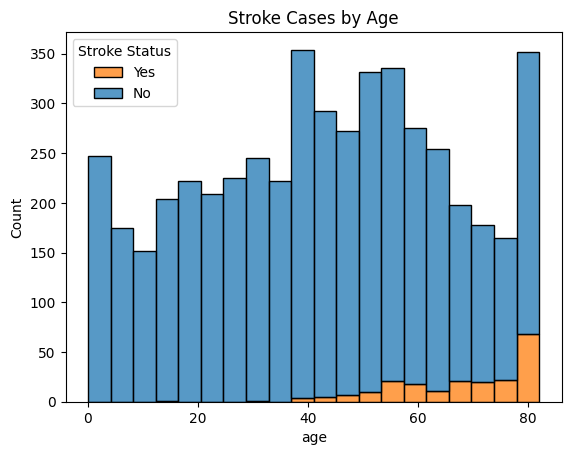

In [19]:
# Relationship between age and stroke

sns.histplot(health_data, x= 'age', hue='stroke', multiple='stack')
plt.title('Stroke Cases by Age')
plt.legend(title = 'Stroke Status', labels = ['Yes', 'No'])
plt.show()

#### What percentage of the dataset has a history of stroke?

In [20]:
stroke_count = health_data['stroke'].value_counts()

stroke_count

stroke
0    4700
1     209
Name: count, dtype: int64

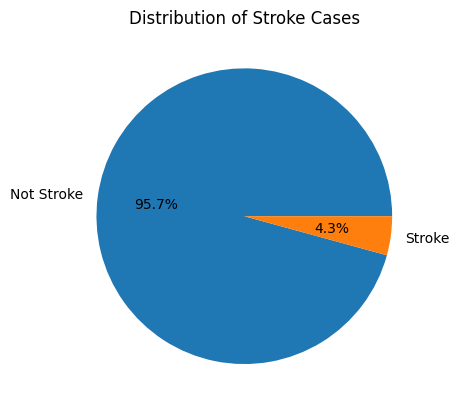

In [21]:
#Present this in a pie chat

stroke_count = (4700, 209)
labels = ('Not Stroke', 'Stroke')

plt.pie(stroke_count, labels = labels, autopct = '%1.1f%%')
plt.title('Distribution of Stroke Cases')
plt.show()

#### What is the male-to-female ratio in the dataset? How does this relate to stroke occurences?

In [22]:
health_data['gender'].value_counts()

gender
Female    2897
Male      2011
Other        1
Name: count, dtype: int64

In [23]:
stroke_rate_gender = health_data.groupby('gender')['stroke'].mean()
stroke_rate_gender

gender
Female    0.041422
Male      0.044257
Other     0.000000
Name: stroke, dtype: float64

In [24]:
stroke_count_gender = stroke_rate_gender * health_data['gender'].value_counts()
stroke_count_gender 

gender
Female    120.0
Male       89.0
Other       0.0
dtype: float64

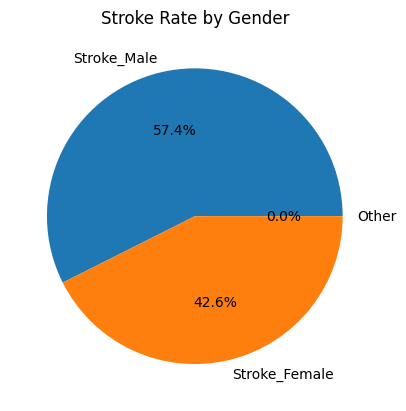

In [25]:
plt.pie(stroke_count_gender, labels = ['Stroke_Male', 'Stroke_Female', 'Other'], autopct = '%1.1f%%')
plt.title('Stroke Rate by Gender')
plt.show()

#### Does the smoking status (e.g: never smoke, formerly smoked, currently smoking) affect stroke risk?

In [26]:
health_data['smoking_status'].value_counts()

smoking_status
never smoked       1852
Unknown            1483
formerly smoked     837
smokes              737
Name: count, dtype: int64

In [27]:
stroke_rate_smoking = health_data.groupby('smoking_status')['stroke'].mean()
stroke_rate_smoking

smoking_status
Unknown            0.019555
formerly smoked    0.068100
never smoked       0.045356
smokes             0.052917
Name: stroke, dtype: float64

In [28]:
smoking_data = {'smoking_status' : ['Unknown','formerly smoked','never smoked', 'smokes'],
                'stroke_rate' : [0.019555, 0.068100, 0.045356, 0.052917]}

smoking_data

{'smoking_status': ['Unknown', 'formerly smoked', 'never smoked', 'smokes'],
 'stroke_rate': [0.019555, 0.0681, 0.045356, 0.052917]}

In [29]:
smoke_stroke = pd.DataFrame(smoking_data)
smoke_stroke

,smoking_status,stroke_rate
0,Unknown,0.019555
1,formerly smoked,0.068100
2,never smoked,0.045356
3,smokes,0.052917


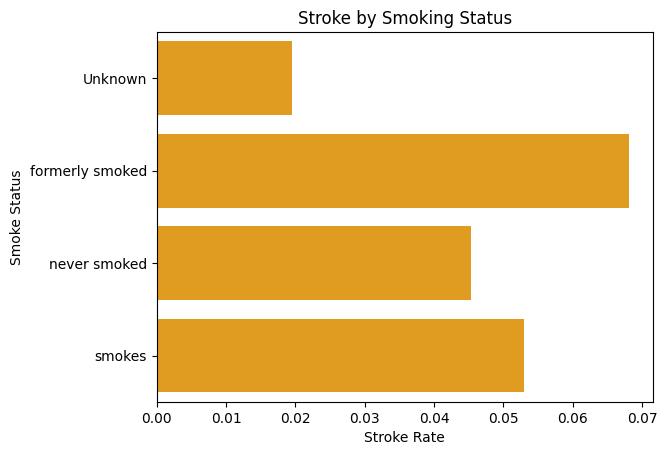

In [30]:
sns.barplot(data = smoke_stroke, y = 'smoking_status', x = 'stroke_rate', color='orange')
plt.title('Stroke by Smoking Status')
plt.xlabel('Stroke Rate')
plt.ylabel('Smoke Status')
plt.show()

#### How do features like hypertension and heart disease correlate with stroke?

### Hypertension

In [31]:
health_data.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
5,56669,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1


In [32]:
health_data['hypertension'].value_counts()

hypertension
0    4458
1     451
Name: count, dtype: int64

In [33]:
stroke_rate_hypertension = health_data.groupby('hypertension')['stroke'].mean()
stroke_rate_hypertension

hypertension
0    0.033423
1    0.133038
Name: stroke, dtype: float64

In [34]:
stroke_count_hypertension = stroke_rate_hypertension * health_data['hypertension'].value_counts()
stroke_count_hypertension 

hypertension
0    149.0
1     60.0
dtype: float64

In [36]:
# plt.pie(stroke_count_hypertension, labels = ['hypertension = No', 'hypertension = Yes'], autopct = '%1.1f%%')
# plt.title('Stroke Rate by Hypertension')
# plt.show()

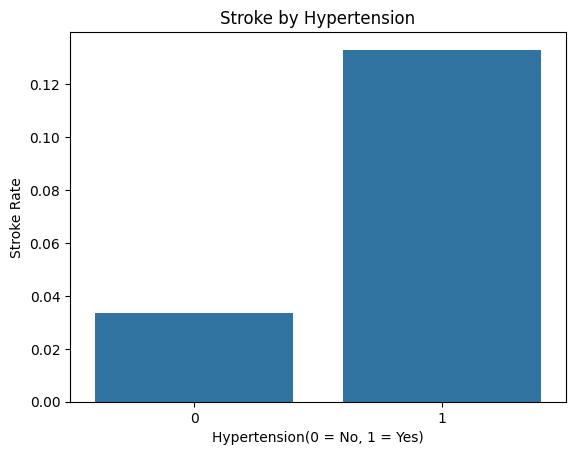

In [38]:
sns.barplot(x = stroke_rate_hypertension.index, y = stroke_rate_hypertension.values)
plt.title('Stroke by Hypertension')
plt.xlabel('Hypertension(0 = No, 1 = Yes)')
plt.ylabel('Stroke Rate')
plt.show()

#### Heart Disease

In [40]:
health_data['heart_disease'].value_counts()

heart_disease
0    4666
1     243
Name: count, dtype: int64

In [41]:
stroke_rate_heart_disease = health_data.groupby('heart_disease')['stroke'].mean()
stroke_rate_heart_disease

heart_disease
0    0.036219
1    0.164609
Name: stroke, dtype: float64

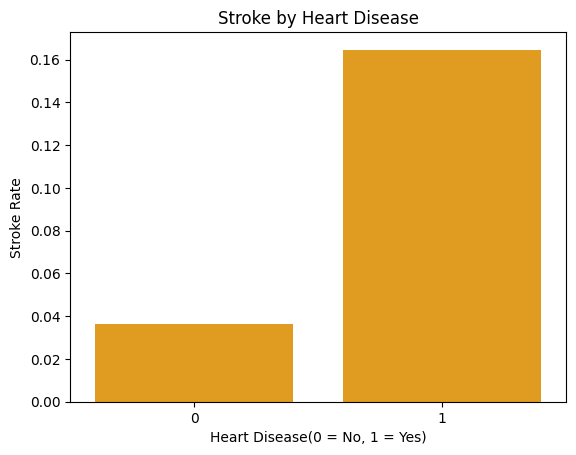

In [49]:
sns.barplot(x = stroke_rate_heart_disease.index, y = stroke_rate_heart_disease.values, color='orange')
plt.title('Stroke by Heart Disease')
plt.xlabel('Heart Disease(0 = No, 1 = Yes)')
plt.ylabel('Stroke Rate')
plt.show()

#### Is there a relationship between BMI (Body Mass Index) and stroke?

In [43]:
health_data.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
5,56669,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1


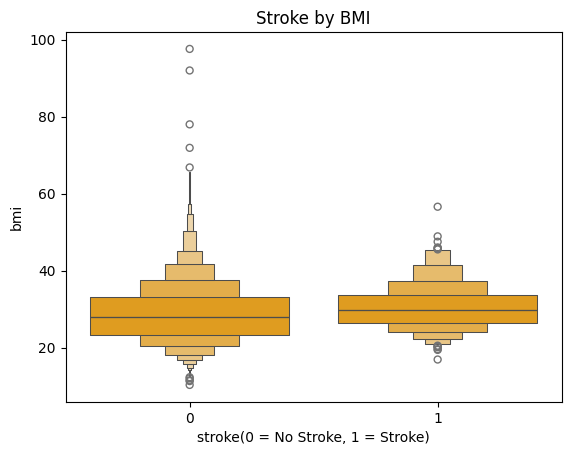

In [48]:
sns.boxenplot(x = 'stroke', y = 'bmi', data = health_data, color='orange')
plt.title('Stroke by BMI')
plt.xlabel('stroke(0 = No Stroke, 1 = Stroke)')
plt.ylabel('bmi')
plt.show()

#### Is there a relationship between Average Glucose Level and stroke?

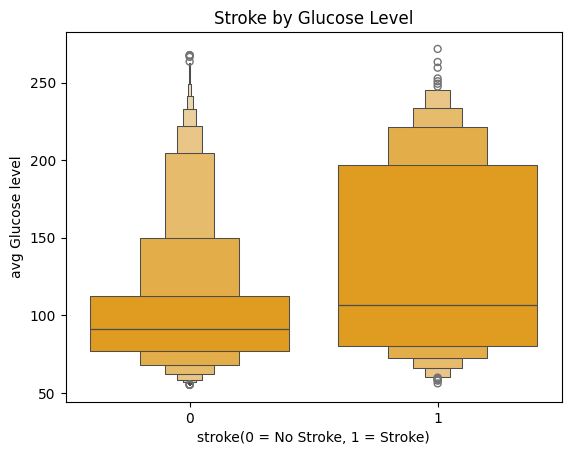

In [47]:
sns.boxenplot(x = 'stroke', y = 'avg_glucose_level', data = health_data, color='orange')
plt.title('Stroke by Glucose Level')
plt.xlabel('stroke(0 = No Stroke, 1 = Stroke)')
plt.ylabel('avg Glucose level')
plt.show()